# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import CGIPlanesDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects witn bounding boxes

Total number of patches: 500


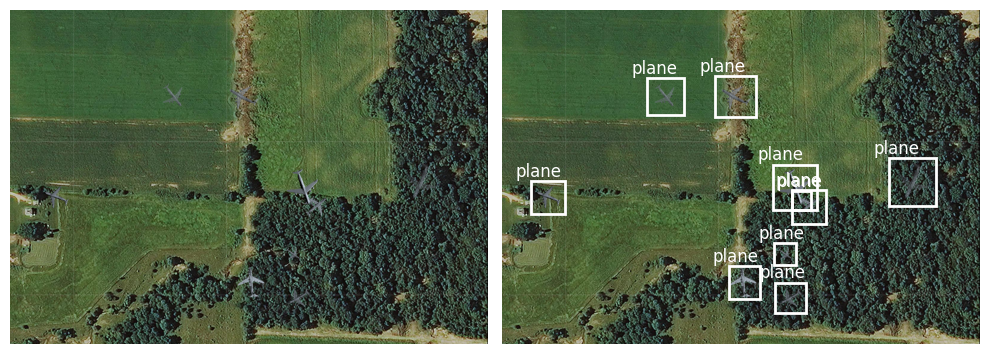

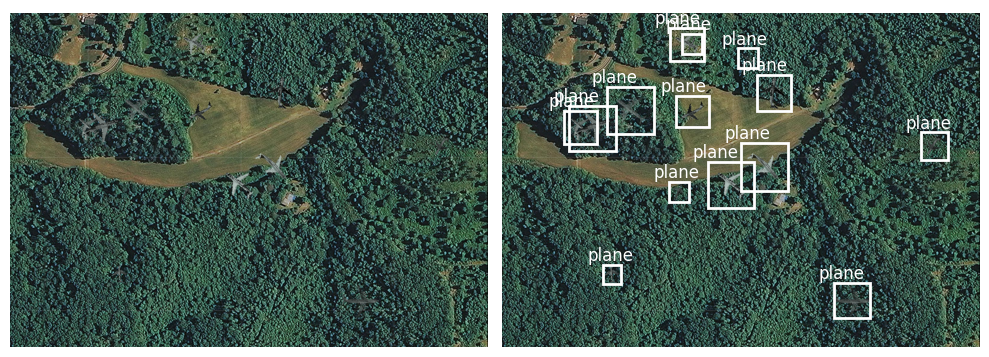

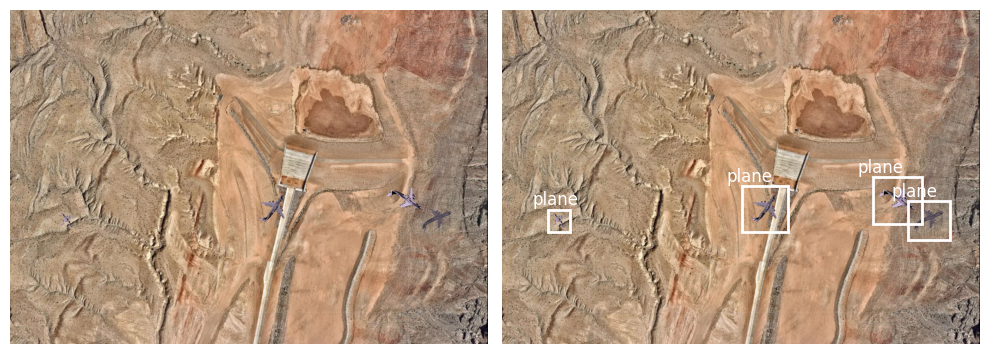

In [ ]:
dataset_config = {
    "image_dir": "./data/CGI_planes/images/",
    "annotations_dir": "./data/CGI_planes/annotations/",
}
dataset = CGIPlanesDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(1);
dataset.show_image(30);
dataset.show_image(90);

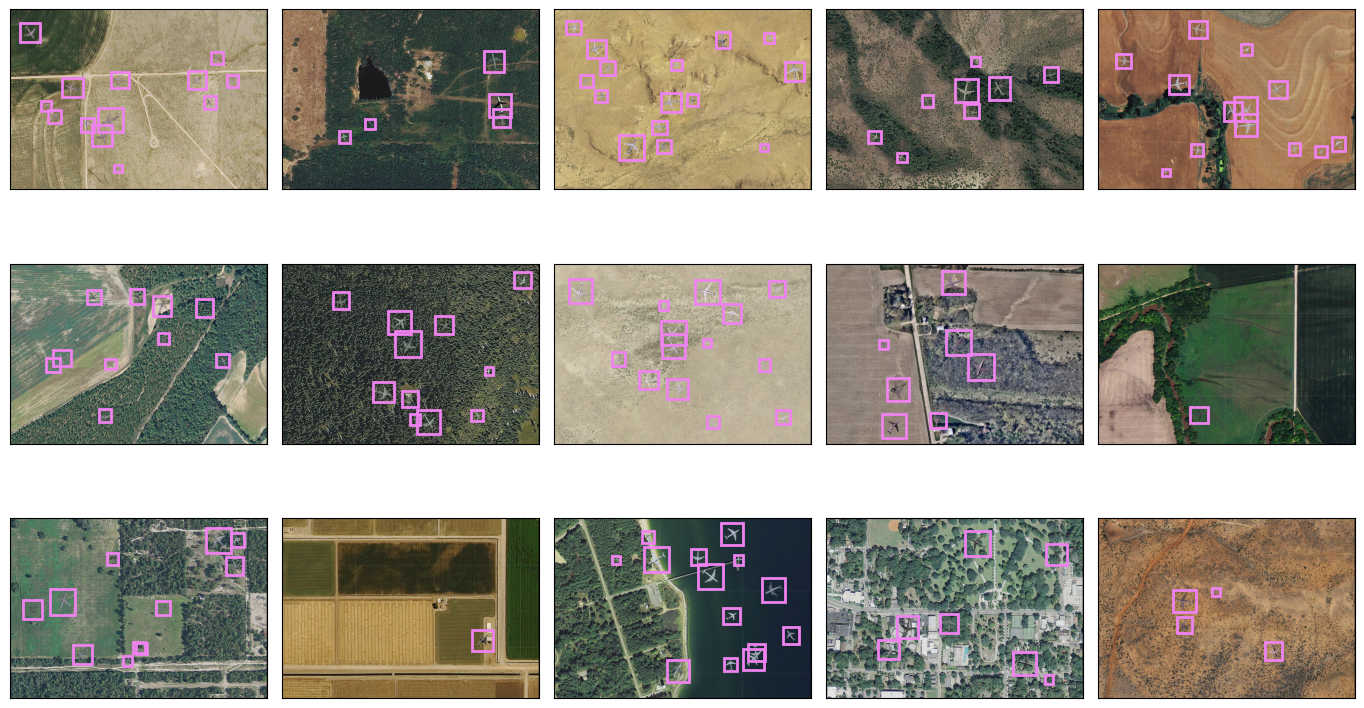

In [18]:
dataset.show_batch(15);

In [28]:
dataset.data_distribution_table()

,Label,Count
0,plane,3999


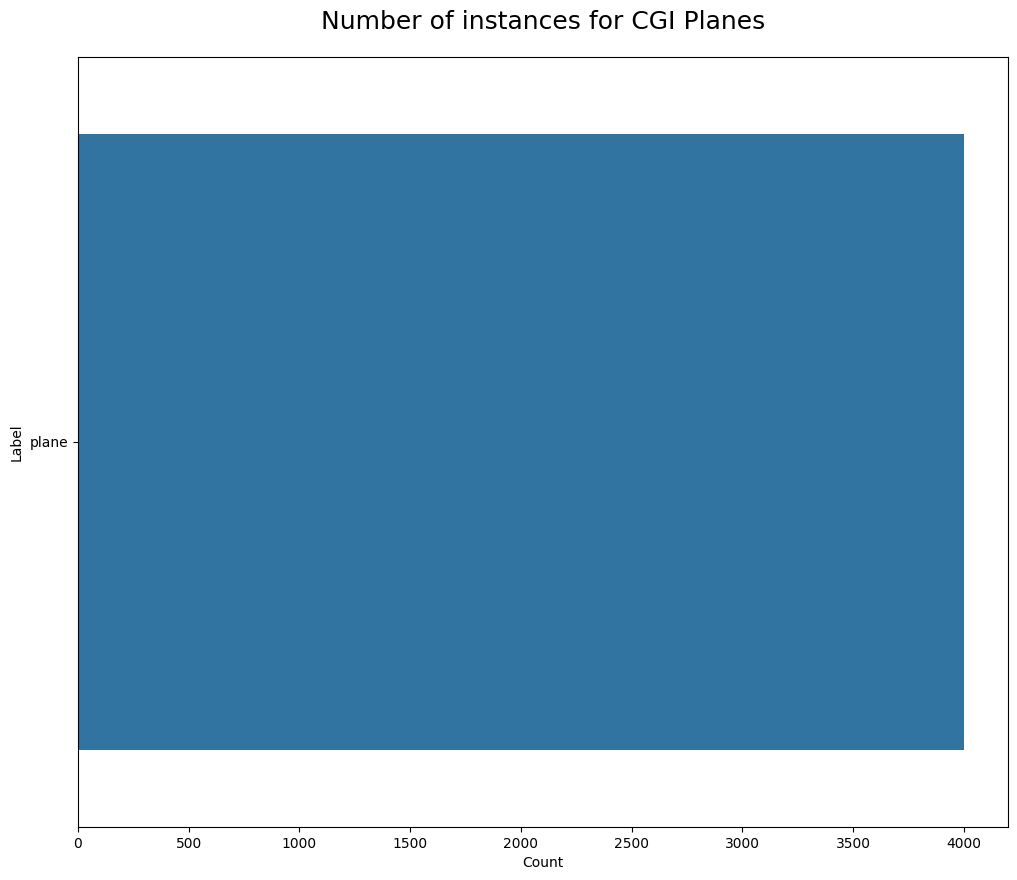

In [20]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "image_dir": "./data/CGI_planes/train/images/",
    "annotations_dir": "./data/CGI_planes/train/annotations/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = CGIPlanesDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 400


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/CGI_planes/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-22 07:12:32,261 INFO Starting training.
training: 100%|██████████| 50/50 [00:18<00:00,  2.77it/s]
2025-05-22 07:12:50,735 INFO epoch: 1, time: 18, loss:  0.54803
testing on train set: 100%|██████████| 50/50 [00:12<00:00,  4.01it/s]
2025-05-22 07:13:06,847 INFO map:0.6759749054908752, map_50:0.9335373044013977, map_75:0.8202616572380066, map_small:0.5692836046218872, map_medium:0.7233861684799194, map_large:-1.0, mar_1:0.10288819670677185, mar_10:0.6549068093299866, mar_100:0.7199378609657288, mar_small:0.6298409700393677, mar_medium:0.7649465203285217, mar_large:-1.0, map_per_class:0.6759749054908752, mar_100_per_class:0.7199378609657288, classes:1.0
training: 100%|██████████| 50/50 [00:20<00:00,  2.49it/s]
2025-05-22 07:13:26,954 INFO epoch: 2, time: 20, loss:  0.28438
testing on train set: 100%|██████████| 50/50 [00:12<00:00,  4.16it/s]
2025-05-22 07:13:41,059 INFO map:0.7190912961959839, map_50:0.9666062593460083, map_75:0.8954931497573853, map_small:0.6419273018836975, map_

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "image_dir": "./data/CGI_planes/test/images_test/",
    "annotations_dir": "./data/CGI_planes/test/annotations_test/",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = CGIPlanesDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/CGI_planes/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 100


2025-05-22 07:17:59,613 INFO Loading checkpoint /home/dragik/data/FAIR_EO/CGI_planes/experiments/checkpoint.pth.tar
2025-05-22 07:18:00,077 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/CGI_planes/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 13/13 [00:03<00:00,  3.83it/s]


[{'map': 0.7512897849082947,
  'map_50': 0.9292128086090088,
  'map_75': 0.8942723870277405,
  'map_small': 0.6868985295295715,
  'map_medium': 0.7840196490287781,
  'map_large': -1.0,
  'mar_1': 0.10898587852716446,
  'mar_10': 0.7103979587554932,
  'mar_100': 0.7860077023506165,
  'mar_small': 0.73082435131073,
  'mar_medium': 0.8167999982833862,
  'mar_large': -1.0,
  'map_per_class': 0.7512897849082947,
  'mar_100_per_class': 0.7860077023506165,
  'classes': 1.0}]

## Predictions

2025-05-22 07:18:09,342 INFO Loading checkpoint /home/dragik/data/FAIR_EO/CGI_planes/experiments/checkpoint.pth.tar
2025-05-22 07:18:09,697 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/CGI_planes/experiments/checkpoint.pth.tar at epoch 11


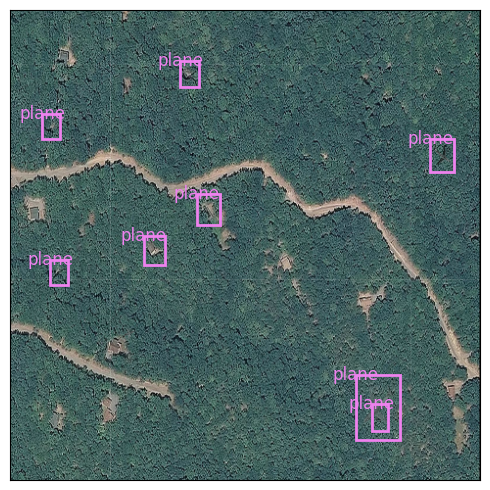

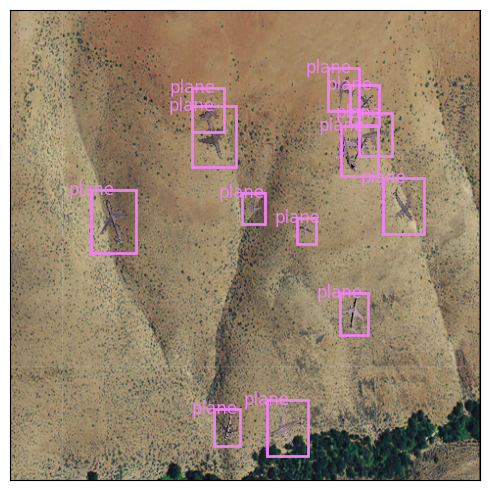

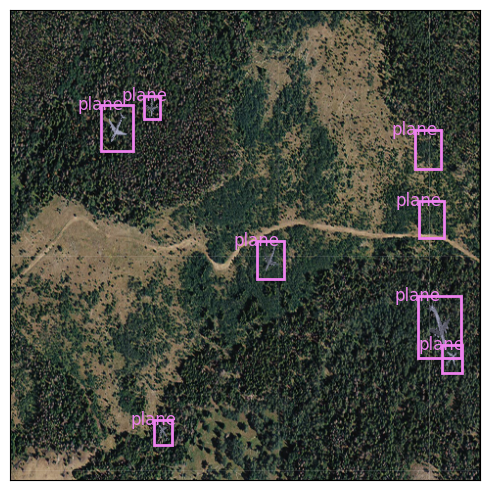

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/CGI_planes/experiments/checkpoint.pth.tar"
labels = ['no-data','plane']
transform = Resize()
model.load_model(model_path)

image = image_loader('./data/CGI_planes/test/images_test/img403.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/CGI_planes/test/images_test/img434.png')
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/CGI_planes/test/images_test/img477.png')
fig = model.detect_objects(image, labels, transform)